# Give Me Some Credit: Feature Distribution Analysis

**Goal:** explore how the distribution of a few key features differs between customers who defaulted and customers who did not, and decide which three features I would start with for credit risk analysis.

## 1. Load and inspect the data

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

%matplotlib inline
pd.set_option("display.max_columns", None)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100})

In [ ]:
path = "GiveMeSomeCredit.csv"

data = pd.read_csv(path)      
df = data.copy()              
print("shape:", df.shape)
df.head()

shape: (149724, 14)


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149724 entries, 0 to 149723
Data columns (total 14 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin                          149724 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  149724 non-null  float64
 2   age                                   149724 non-null  int64  
 3   SEX                                   149724 non-null  object 
 4   EDUCATION                             149724 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  149724 non-null  int64  
 6   DebtRatio                             149724 non-null  float64
 7   MonthlyIncome                         120117 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       149724 non-null  int64  
 9   NumberOfTimes90DaysLate               149724 non-null  int64  
 10  NumberRealEstateLoansOrLines          149724 non-null  int64  
 11  

missing values

In [5]:
missing = pd.DataFrame({"missing": df.isna().sum(), "missing_%": (df.isna().mean() * 100).round(2)})
missing[missing["missing"] > 0]

,missing,missing_%
MonthlyIncome,29607,19.77
NumberOfDependents,3893,2.60


target balance

In [6]:
target = "SeriousDlqin"
pd.DataFrame({"count": df[target].value_counts(),
              "percent": (df[target].value_counts(normalize=True) * 100).round(2)})

,count,percent
SeriousDlqin,,
0,139845,93.4
1,9879,6.6


The classes are very imbalanced (about 93% / 7%). Because of this, when I compare the two groups I use **density-normalised** histograms and **default rates** (not raw counts), otherwise the defaulters would be invisible.

# Cleaning (same decisions as the class notebook)
- `NumberOfDefault` is almost a copy of the target (correlation about 0.92), so it is **target leakage** and is removed.
- Customers with an impossible age (under 18 or over 100) are removed.
- I do **not** fill missing values here: for a distribution analysis it is better to see the missing values as they are.

In [7]:
if "NumberOfDefault" in df.columns:
    df = df.drop(columns="NumberOfDefault")

n_before = len(df)
df = df[(df["age"] >= 18) & (df["age"] <= 100)].copy()
print("rows removed because of impossible age:", n_before - len(df))
print("rows used in the analysis:", len(df))

rows removed because of impossible age: 14
rows used in the analysis: 149710


### Helper functions

In [8]:
good = df[df[target] == 0]
bad = df[df[target] == 1]
COLORS = {0: "tab:blue", 1: "tab:red"}
LABELS = {0: "No default", 1: "Default"}


def feature_summary(col):
    """missing %, zeros %, mean, median, skewness... for all / no default / default"""
    rows = {}
    for name, g in [("All", df), ("No default", good), ("Default", bad)]:
        s = g[col]
        rows[name] = {"missing_%": s.isna().mean() * 100, "zeros_%": (s == 0).mean() * 100,
                      "mean": s.mean(), "median": s.median(), "std": s.std(),
                      "skew": s.skew(), "p99": s.quantile(0.99), "max": s.max()}
    return pd.DataFrame(rows).T.round(3)


def iqr_outlier_pct(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100


def default_rate(key):
    # SQL: SELECT key, COUNT(*) AS customers, AVG(SeriousDlqin) * 100 AS default_rate
    #      FROM df GROUP BY key
    out = df[target].groupby(key, observed=False).agg(customers="size", default_rate="mean")
    out["default_rate"] = out["default_rate"] * 100
    return out


def hist_by_target(ax, col, title, xlabel, bins=40, rng=None):
    for v in (0, 1):
        ax.hist(df.loc[df[target] == v, col].dropna(), bins=bins, range=rng, density=True,
                alpha=0.5, color=COLORS[v], label=LABELS[v])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)


def box_by_target(ax, col, title, ylabel, log=False):
    groups = [g[col].dropna() for g in (good, bad)]
    if log:
        groups = [s[s > 0] for s in groups]   # log scale cannot show zeros
    ax.boxplot(groups, flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_xticks([1, 2])
    ax.set_xticklabels([LABELS[0], LABELS[1]])
    if log:
        ax.set_yscale("log")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Outcome")
    ax.set_ylabel(ylabel)


def bar_rates(ax, rates, title, xlabel):
    x = rates.index.astype(str)
    ax.bar(x, rates["default_rate"], color="tab:red", alpha=0.7)
    for i, r in enumerate(rates["default_rate"]):
        ax.text(i, r, f"{r:.1f}%", ha="center", va="bottom", fontsize=8)
    ax.axhline(df[target].mean() * 100, color="black", ls="--", lw=1, label="Overall default rate")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Default rate (%)")
    ax.legend(fontsize=8)

## 2. Part 1: Feature distribution analysis

I picked four features that cover the situations the exercise asks about: a fairly symmetric one (`age`), one with extreme outliers (`RevolvingUtilizationOfUnsecuredLines`), one made mostly of zeros (`NumberOfTimes90DaysLate`) and one with missing values (`MonthlyIncome`).

### 2.1 `age`

In [9]:
feature_summary("age")

,missing_%,zeros_%,mean,median,std,skew,p99,max
All,0.0,0.0,52.323,52.0,14.747,0.188,87.00,99.0
No default,0.0,0.0,52.766,52.0,14.772,0.163,87.00,99.0
Default,0.0,0.0,46.051,46.0,12.850,0.461,80.23,99.0


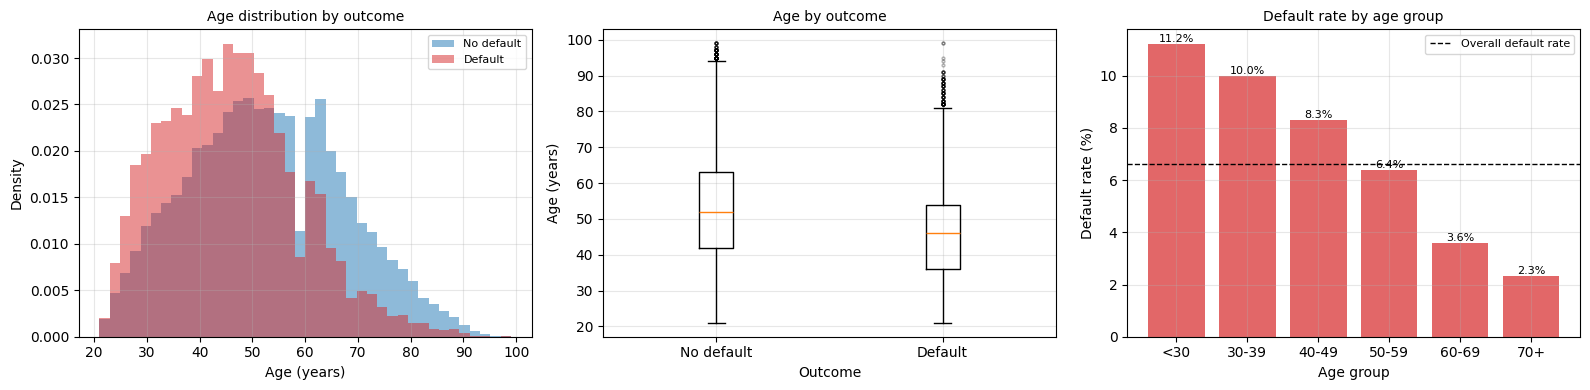

,customers,default_rate
age,,
<30,8677,11.21
30-39,23139,9.97
40-49,34341,8.31
50-59,35264,6.39
60-69,28891,3.60
70+,19398,2.31


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
hist_by_target(axes[0], "age", "Age distribution by outcome", "Age (years)", bins=40)
box_by_target(axes[1], "age", "Age by outcome", "Age (years)")
age_groups = pd.cut(df["age"], [0, 29, 39, 49, 59, 69, np.inf], labels=["<30", "30-39", "40-49", "50-59", "60-69", "70+"])
age_rates = default_rate(age_groups)
bar_rates(axes[2], age_rates, "Default rate by age group", "Age group")
plt.tight_layout()
plt.show()
age_rates.round(2)

In [11]:
age_s = feature_summary("age")
age_facts = {
    "skew": df["age"].skew(),
    "miss": df["age"].isna().mean() * 100,
    "zeros": (df["age"] == 0).mean() * 100,
    "out": iqr_outlier_pct(df["age"]),
    "mean_good": good["age"].mean(), "mean_bad": bad["age"].mean(),
    "r_young": age_rates["default_rate"].iloc[0], "r_old": age_rates["default_rate"].iloc[-1],
    "steady": age_rates["default_rate"].is_monotonic_decreasing,
}
f = age_facts
shape = "roughly symmetric" if abs(f["skew"]) < 0.5 else ("right-skewed" if f["skew"] > 0 else "left-skewed")
who = "younger" if f["mean_bad"] < f["mean_good"] else "older"
trend = "falls steadily" if f["steady"] else "changes"
age_text = (f"Age is {shape} (skewness {f['skew']:.2f}) with {f['miss']:.0f}% missing values, {f['zeros']:.0f}% zeros and only "
            f"{f['out']:.2f}% IQR outliers. Defaulters are {who}: mean age {f['mean_bad']:.1f} vs {f['mean_good']:.1f} years, and the "
            f"default rate {trend} from {f['r_young']:.1f}% (under 30) to {f['r_old']:.1f}% (70+). "
            f"Credit-risk reading: younger borrowers usually have a shorter credit history, less stable income and smaller savings "
            f"buffers, while older borrowers tend to be more established.")
display(Markdown("**Interpretation.** " + age_text))

**Interpretation.** Age is roughly symmetric (skewness 0.19) with 0% missing values, 0% zeros and only 0.02% IQR outliers. Defaulters are younger: mean age 46.1 vs 52.8 years, and the default rate falls steadily from 11.2% (under 30) to 2.3% (70+). Credit-risk reading: younger borrowers usually have a shorter credit history, less stable income and smaller savings buffers, while older borrowers tend to be more established.

### 2.2 `RevolvingUtilizationOfUnsecuredLines`

This is the balance on credit cards and personal lines divided by the credit limit, so a value above 1 means the customer is over the limit.

In [12]:
feature_summary("RevolvingUtilizationOfUnsecuredLines")

,missing_%,zeros_%,mean,median,std,skew,p99,max
All,0.0,7.265,5.720,0.154,212.902,67.707,1.093,29110.0
No default,0.0,7.549,5.812,0.133,217.447,67.320,1.026,29110.0
Default,0.0,3.240,4.418,0.830,132.819,44.589,1.730,8328.0


In [13]:
col = "RevolvingUtilizationOfUnsecuredLines"
print("share of customers with utilization > 1 :", round((df[col] > 1).mean() * 100, 2), "%")
print("share of customers with utilization > 10:", round((df[col] > 10).mean() * 100, 3), "%")
print("99th percentile:", round(df[col].quantile(0.99), 2), "| maximum:", round(df[col].max(), 1))

share of customers with utilization > 1 : 2.22 %
share of customers with utilization > 10: 0.16 %
99th percentile: 1.09 | maximum: 29110.0


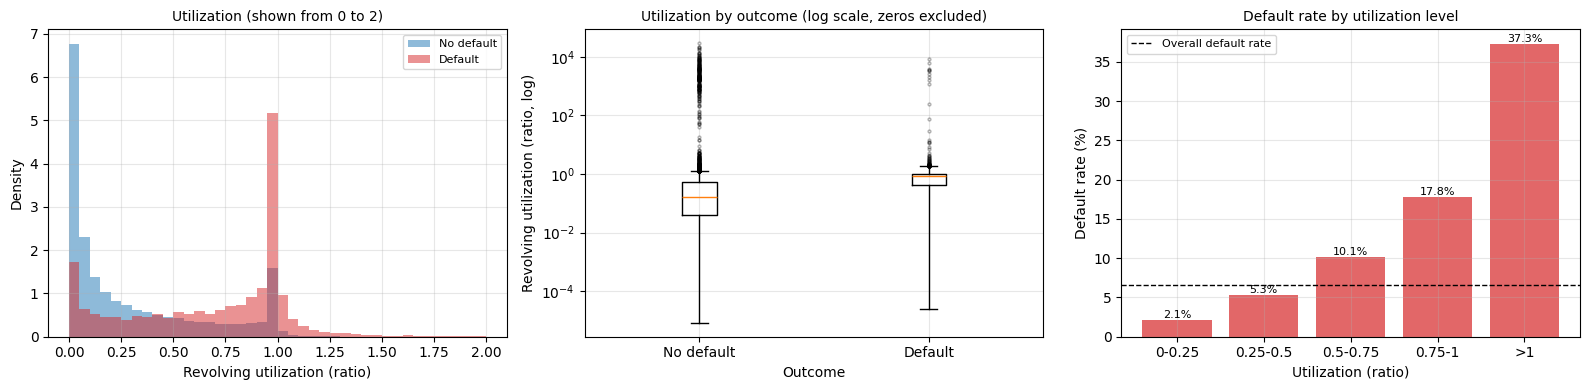

,customers,default_rate
RevolvingUtilizationOfUnsecuredLines,,
0-0.25,87639,2.14
0.25-0.5,21055,5.29
0.5-0.75,13764,10.13
0.75-1,23932,17.80
>1,3320,37.26


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
hist_by_target(axes[0], col, "Utilization (shown from 0 to 2)", "Revolving utilization (ratio)", bins=40, rng=(0, 2))
box_by_target(axes[1], col, "Utilization by outcome (log scale, zeros excluded)", "Revolving utilization (ratio, log)", log=True)
util_groups = pd.cut(df[col], [-0.001, 0.25, 0.5, 0.75, 1, np.inf], labels=["0-0.25", "0.25-0.5", "0.5-0.75", "0.75-1", ">1"])
util_rates = default_rate(util_groups)
bar_rates(axes[2], util_rates, "Default rate by utilization level", "Utilization (ratio)")
plt.tight_layout()
plt.show()
util_rates.round(2)

In [15]:
us = df[col]
util_facts = {
    "skew": us.skew(), "med": us.median(), "mx": us.max(),
    "gt1": (us > 1).mean() * 100, "gt10": (us > 10).mean() * 100,
    "mean_good": good[col].mean(), "mean_bad": bad[col].mean(),
    "med_good": good[col].median(), "med_bad": bad[col].median(),
    "r_low": util_rates["default_rate"].iloc[0], "r_high": util_rates["default_rate"].iloc[-1],
    # share of each group sitting within 5% of the credit limit (utilization between 0.95 and 1.05)
    "near_good": good[col].between(0.95, 1.05).mean() * 100, "near_bad": bad[col].between(0.95, 1.05).mean() * 100,
}
f = util_facts
util_text = (f"Utilization is extremely right-skewed (skewness {f['skew']:.0f}): median {f['med']:.2f}, maximum {f['mx']:,.0f}; "
             f"{f['gt1']:.1f}% of customers are above 1.0 and {f['gt10']:.2f}% above 10 (likely data errors). "
             f"Outliers make the means misleading ({f['mean_good']:.1f} vs {f['mean_bad']:.1f}); the medians show the real gap: "
             f"{f['med_good']:.2f} (no default) vs {f['med_bad']:.2f} (default). The default rate rises steadily with utilization, "
             f"from {f['r_low']:.1f}% below 0.25 to {f['r_high']:.1f}% above 1.0 ({f['r_high'] / f['r_low']:.0f}x), and "
             f"{f['near_bad']:.0f}% of defaulters sit right at their limit (0.95-1.05) vs {f['near_good']:.0f}% of non-defaulters. "
             f"Hypothesis: customers using most of their limit are financially stretched and have little room for a shock.")
display(Markdown("**Interpretation.** " + util_text))

**Interpretation.** Utilization is extremely right-skewed (skewness 68): median 0.15, maximum 29,110; 2.2% of customers are above 1.0 and 0.16% above 10 (likely data errors). Outliers make the means misleading (5.8 vs 4.4); the medians show the real gap: 0.13 (no default) vs 0.83 (default). The default rate rises steadily with utilization, from 2.1% below 0.25 to 37.3% above 1.0 (17x), and 31% of defaulters sit right at their limit (0.95-1.05) vs 9% of non-defaulters. Hypothesis: customers using most of their limit are financially stretched and have little room for a shock.

### 2.3 `NumberOfTimes90DaysLate`

How many times the customer was 90 days or more late on a payment.

In [16]:
feature_summary("NumberOfTimes90DaysLate")

,missing_%,zeros_%,mean,median,std,skew,p99,max
All,0.0,94.611,0.090,0.0,0.486,9.335,2.0,17.0
No default,0.0,96.608,0.050,0.0,0.333,12.522,1.0,15.0
Default,0.0,66.339,0.665,0.0,1.286,3.210,6.0,17.0


In [17]:
col = "NumberOfTimes90DaysLate"
print(df[col].value_counts().sort_index().head(8))

NumberOfTimes90DaysLate
0    141642
1      5243
2      1554
3       667
4       291
5       131
6        80
7        38
Name: count, dtype: int64


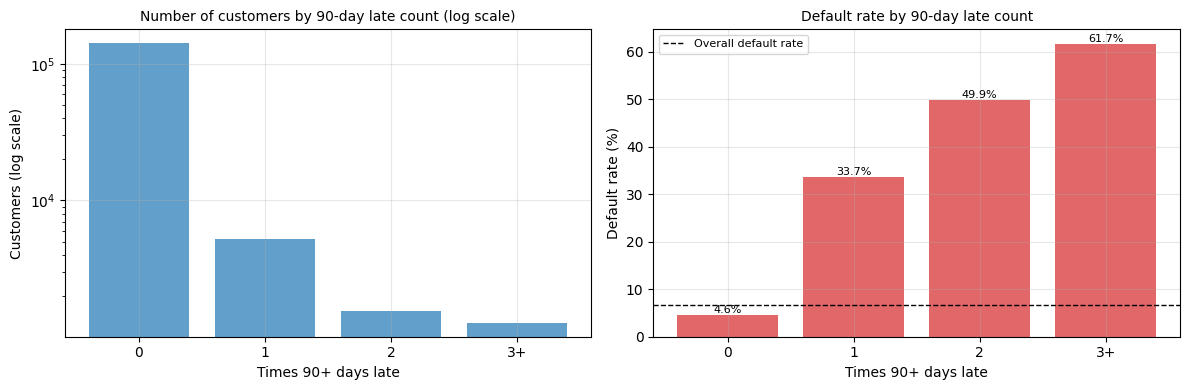

,customers,default_rate
NumberOfTimes90DaysLate,,
0,141642,4.63
1,5243,33.66
2,1554,49.94
3+,1271,61.68


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
late_group = df[col].clip(upper=3).astype(int).astype(str).replace({"3": "3+"})   # 3 or more together
late_rates = default_rate(late_group)
axes[0].bar(late_rates.index, late_rates["customers"], color="tab:blue", alpha=0.7)
axes[0].set_yscale("log")
axes[0].set_title("Number of customers by 90-day late count (log scale)", fontsize=10)
axes[0].set_xlabel("Times 90+ days late")
axes[0].set_ylabel("Customers (log scale)")
bar_rates(axes[1], late_rates, "Default rate by 90-day late count", "Times 90+ days late")
plt.tight_layout()
plt.show()
late_rates.round(2)

In [19]:
ls = df[col]
has_late = ls > 0
late_facts = {
    "zeros": (ls == 0).mean() * 100, "nz": has_late.mean() * 100, "mx": int(ls.max()),
    "r1": df.loc[has_late, target].mean() * 100, "r0": df.loc[~has_late, target].mean() * 100,
    "z_bad": (bad[col] == 0).mean() * 100, "z_good": (good[col] == 0).mean() * 100,
}
late_facts["ratio"] = late_facts["r1"] / late_facts["r0"]
f = late_facts
late_text = (f"The feature is dominated by zeros ({f['zeros']:.1f}%) and is strongly right-skewed (maximum {f['mx']}). "
             f"At least one 90-day delinquency is rare ({f['nz']:.1f}% of customers), but the default rate is "
             f"{f['r1']:.1f}% for those customers vs {f['r0']:.1f}% for the rest ({f['ratio']:.1f}x higher). "
             f"It is a strong signal when present, but not enough alone: {f['z_bad']:.1f}% of defaulters have no 90-day late on record "
             f"(vs {f['z_good']:.1f}% of non-defaulters), so it identifies a minority of defaulters very well and misses most of them. "
             f"Past severe delinquency reflects repayment behaviour.")
display(Markdown("**Interpretation.** " + late_text))

**Interpretation.** The feature is dominated by zeros (94.6%) and is strongly right-skewed (maximum 17). At least one 90-day delinquency is rare (5.4% of customers), but the default rate is 41.2% for those customers vs 4.6% for the rest (8.9x higher). It is a strong signal when present, but not enough alone: 66.3% of defaulters have no 90-day late on record (vs 96.6% of non-defaulters), so it identifies a minority of defaulters very well and misses most of them. Past severe delinquency reflects repayment behaviour.

*Caution:* the target itself is defined from 90-days-past-due events, so part of this strong relationship may come from overlapping definitions and timing. I treat it as a very strong signal but I would check how the two are defined before using it in a real model.

### 2.4 `MonthlyIncome`

In [20]:
feature_summary("MonthlyIncome")

,missing_%,zeros_%,mean,median,std,skew,p99,max
All,19.772,1.087,6650.258,5400.0,11494.222,75.482,25000.00,1794060.0
No default,20.020,1.118,6723.215,5470.0,11788.791,74.948,25000.00,1794060.0
Default,16.258,0.648,5663.874,4500.0,6192.820,16.619,22958.11,250000.0


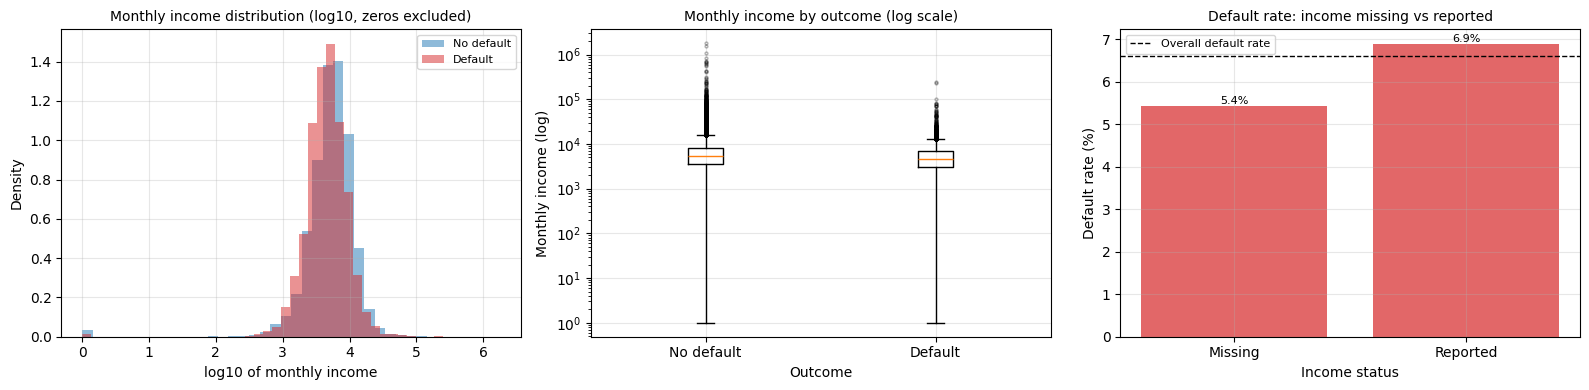

,customers,default_rate
MonthlyIncome,,
Missing,29600,5.43
Reported,120110,6.89


In [21]:
col = "MonthlyIncome"
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for v in (0, 1):
    s = df.loc[(df[target] == v) & (df[col] > 0), col]
    axes[0].hist(np.log10(s), bins=40, density=True, alpha=0.5, color=COLORS[v], label=LABELS[v])
axes[0].set_title("Monthly income distribution (log10, zeros excluded)", fontsize=10)
axes[0].set_xlabel("log10 of monthly income")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=8)
box_by_target(axes[1], col, "Monthly income by outcome (log scale)", "Monthly income (log)", log=True)
income_groups = df[col].isna().map({True: "Missing", False: "Reported"})
income_rates = default_rate(income_groups)
bar_rates(axes[2], income_rates, "Default rate: income missing vs reported", "Income status")
plt.tight_layout()
plt.show()
income_rates.round(2)

In [22]:
inc = df[col]
income_facts = {
    "skew": inc.skew(), "miss": inc.isna().mean() * 100, "zeros": (inc == 0).mean() * 100,
    "out": iqr_outlier_pct(inc), "mx": inc.max(),
    "med_good": good[col].median(), "med_bad": bad[col].median(),
    "r_miss": income_rates.loc["Missing", "default_rate"], "r_obs": income_rates.loc["Reported", "default_rate"],
}
f = income_facts
lower = "lower" if f["med_bad"] < f["med_good"] else "higher"
miss_dir = "less" if f["r_miss"] < f["r_obs"] else "more"
miss_note = ("so the missingness itself carries information and should be kept as a flag" if abs(f["r_miss"] - f["r_obs"]) >= 1
             else "a small difference, so missingness adds little information")
income_text = (f"Income is right-skewed (skewness {f['skew']:.1f}) with {f['miss']:.1f}% missing values and {f['zeros']:.1f}% zeros; "
               f"{f['out']:.1f}% of known values are IQR outliers (maximum {f['mx']:,.0f}). The median is {lower} for defaulters "
               f"({f['med_bad']:,.0f} vs {f['med_good']:,.0f}), but the gap is modest. Customers with missing income default {miss_dir} often "
               f"({f['r_miss']:.1f}% vs {f['r_obs']:.1f}%), {miss_note}. "
               f"Hypothesis: lower income means a thinner buffer for repayments.")
display(Markdown("**Interpretation.** " + income_text))

**Interpretation.** Income is right-skewed (skewness 75.5) with 19.8% missing values and 1.1% zeros; 4.1% of known values are IQR outliers (maximum 1,794,060). The median is lower for defaulters (4,500 vs 5,470), but the gap is modest. Customers with missing income default less often (5.4% vs 6.9%), so the missingness itself carries information and should be kept as a flag. Hypothesis: lower income means a thinner buffer for repayments.

## 3. Comparing features with Information Value (IV)

To support the final choice with numbers, I compute the Information Value of each feature (same idea as the WOE/IV section of the class notebook). Rule of thumb: IV below 0.02 is not useful, 0.02-0.1 weak, 0.1-0.3 medium, above 0.3 strong. Continuous features are cut into up to 10 quantile bins, count features are capped at 3, and missing values get their own bin.

In [23]:
def information_value(x, y, bins=10, cap=None):
    x = x.clip(upper=cap) if cap is not None else x
    if cap is None and x.nunique() > 10:
        cat = pd.qcut(x, q=bins, duplicates="drop").astype(str)    # NaN becomes the string "nan" = its own bin
    else:
        cat = x.astype(str)
    tab = pd.crosstab(cat, y)
    g = tab[0] / tab[0].sum()
    b = tab[1] / tab[1].sum()
    eps = 1e-6
    woe = np.log((g + eps) / (b + eps))
    return ((g - b) * woe).sum()


count_cols = ["NumberOfTimes90DaysLate", "NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse"]
other_cols = ["age", "RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome",
              "NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines", "NumberOfDependents"]

iv = {c: information_value(df[c], df[target], cap=3) for c in count_cols}
iv.update({c: information_value(df[c], df[target]) for c in other_cols})
iv_table = pd.Series(iv, name="IV").sort_values(ascending=False).round(3).to_frame()
iv_table

,IV
RevolvingUtilizationOfUnsecuredLines,1.093
NumberOfTimes90DaysLate,0.848
NumberOfTime30-59DaysPastDueNotWorse,0.725
NumberOfTime60-89DaysPastDueNotWorse,0.567
age,0.254
DebtRatio,0.082
MonthlyIncome,0.072
NumberOfOpenCreditLinesAndLoans,0.055
NumberOfDependents,0.030
NumberRealEstateLoansOrLines,0.012


one table with everything I looked at: shape, zeros, missing, outliers, IV

In [24]:
rows = []
for c in ["age", "RevolvingUtilizationOfUnsecuredLines", "NumberOfTimes90DaysLate", "MonthlyIncome"]:
    s = df[c]
    rows.append({"feature": c, "missing_%": s.isna().mean() * 100, "zeros_%": (s == 0).mean() * 100,
                 "skew": s.skew(), "IQR_outliers_%": iqr_outlier_pct(s),
                 "median_no_default": good[c].median(), "median_default": bad[c].median(), "IV": iv[c]})
pd.DataFrame(rows).set_index("feature").round(3)

,missing_%,zeros_%,skew,IQR_outliers_%,median_no_default,median_default,IV
feature,,,,,,,
age,0.000,0.000,0.188,0.021,52.000,46.00,0.254
RevolvingUtilizationOfUnsecuredLines,0.000,7.265,67.707,0.513,0.133,0.83,1.093
NumberOfTimes90DaysLate,0.000,94.611,9.335,5.389,0.000,0.00,0.848
MonthlyIncome,19.772,1.087,75.482,4.059,5470.000,4500.00,0.072


Reading the table: the late-payment and utilization features have the strongest signal, while `MonthlyIncome` and `DebtRatio` are weaker and also the messiest (missing values, extreme values). `age` has a medium signal and a clean, easy-to-explain pattern. Features such as `NumberOfTime30-59...` and `NumberOfTime60-89...` carry similar information to `NumberOfTimes90DaysLate`, so choosing all three of them would mostly repeat the same signal.

## 4. Part 2: Final insights

In [25]:
iv_late, iv_util, iv_age = iv["NumberOfTimes90DaysLate"], iv["RevolvingUtilizationOfUnsecuredLines"], iv["age"]
iv_inc, iv_debt = iv["MonthlyIncome"], iv["DebtRatio"]
weaker = "weaker" if max(iv_inc, iv_debt) < min(iv_late, iv_util, iv_age) else "less consistent"

final_text = (f"I would start with RevolvingUtilizationOfUnsecuredLines (IV {iv_util:.2f}), NumberOfTimes90DaysLate (IV {iv_late:.2f}) and age (IV {iv_age:.2f}). "
              f"Utilization shows current credit stress (default rate {util_facts['r_low']:.1f}% to {util_facts['r_high']:.1f}% across levels) and 90-day lates show past "
              f"repayment behaviour ({late_facts['r1']:.1f}% vs {late_facts['r0']:.1f}%), while age adds a different, easy-to-collect signal "
              f"({age_facts['r_young']:.1f}% for under 30 vs {age_facts['r_old']:.1f}% for 70+). "
              f"MonthlyIncome and DebtRatio are {weaker} (IV {iv_inc:.2f} and {iv_debt:.2f}) and have missing or extreme values.")
display(Markdown("**Final insight.** " + final_text))

**Final insight.** I would start with RevolvingUtilizationOfUnsecuredLines (IV 1.09), NumberOfTimes90DaysLate (IV 0.85) and age (IV 0.25). Utilization shows current credit stress (default rate 2.1% to 37.3% across levels) and 90-day lates show past repayment behaviour (41.2% vs 4.6%), while age adds a different, easy-to-collect signal (11.2% for under 30 vs 2.3% for 70+). MonthlyIncome and DebtRatio are weaker (IV 0.07 and 0.08) and have missing or extreme values.

Note: in a real lending decision, age may be restricted or require care for fairness reasons, so it is shown here as a statistical signal, not as a recommendation to use it in a decision rule.

## Summary

- **Four features analysed** with histograms, boxplots and default-rate charts, every chart with title, axis labels and readable categories.
- **Numerical evidence:** e.g. the default rate is many times higher for customers with a past 90-day delinquency, and falls steadily with age.
- **Data problems found:** extreme outliers in utilization, a large share of zeros in the delinquency counts, and missing values in income.
- **Final choice:** past 90-day delinquency, revolving utilization and age.